# Experiment 2, steps 3–6: generation counterfactuals and attribution graphs

Reads `results/cf/` from `scripts/05_summarise_counterfactuals.py` and
`data/processed/cf/attribution_graphs-*.jsonl` from `scripts/06_attribution_graphs.py`.

Each recorded mutation query is resampled 4 times per prompt variant, with the
same sampling seeds across variants, and every child is evaluated. Effects are
`variant − full`, averaged within a query, with 95% bootstrap CIs over LLaMEA runs.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MI_ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(MI_ROOT))
from common.paths import data_dir, results_dir
from common.plotting import INK, NEUTRAL, SERIES, setup

setup()
EXP, TAG = "exp02_feedback_attribution", "cf"
res = results_dir(EXP, TAG)
eff = pd.read_csv(res / "cf_effects.csv")
means = pd.read_csv(res / "cf_means.csv")
samples = pd.read_csv(res / "cf_samples.csv")
means.round(3)

,stratum,variant,failed,score,over_budget,similarity,same_name,prefix,identical,error_line_kept,same_error,pf_L15,cf_L21,ob_L9,n_gen_tokens,n
0,error,error_generic,0.596,0.094,0.916,0.747,0.154,0.067,0.005,0.495,0.401,0.229,-0.224,0.825,656.721,384
1,error,full,0.432,0.119,0.940,0.778,0.323,1.000,1.000,0.351,0.247,0.193,-0.198,0.948,631.107,384
2,error,no_error,0.656,0.076,0.924,0.716,0.029,0.038,0.000,0.548,0.461,0.237,-0.206,0.827,704.576,384
3,scored,budget_msg,0.138,0.359,0.932,0.854,0.194,0.105,0.044,NaN,NaN,0.478,-0.744,0.878,914.126,340
4,scored,full,0.128,0.330,0.934,0.846,0.130,1.000,1.000,NaN,NaN,0.453,-0.714,0.836,915.466,384
5,scored,no_feedback,0.143,0.334,0.927,0.850,0.167,0.198,0.099,NaN,NaN,0.436,-0.757,0.795,915.206,384
6,scored,score_high,0.151,0.319,0.933,0.845,0.167,0.328,0.198,NaN,NaN,0.491,-0.717,0.833,915.323,384
7,scored,score_low,0.141,0.328,0.921,0.829,0.096,0.256,0.143,NaN,NaN,0.414,-0.700,0.841,922.102,384
8,scored,steer_down,0.107,0.351,0.921,0.871,0.185,0.112,0.062,NaN,NaN,-0.373,-0.737,0.821,860.805,384
9,scored,steer_random,0.182,0.316,0.920,0.850,0.115,0.109,0.055,NaN,NaN,0.388,-0.818,0.838,919.909,384


## 1. Scored parents: what changes the internal fitness estimate, and what changes the child?

`pf_L15` is experiment 1's parent-fitness probe (prompt mean, layer 15) read out during
the resampled query, in AOCC units. Editing the written score changes the score the model
reads by about ±0.5 AOCC (dashed marks); steering adds the top-minus-bottom-tercile
difference of means (×2) directly to the residual stream at layer 15.

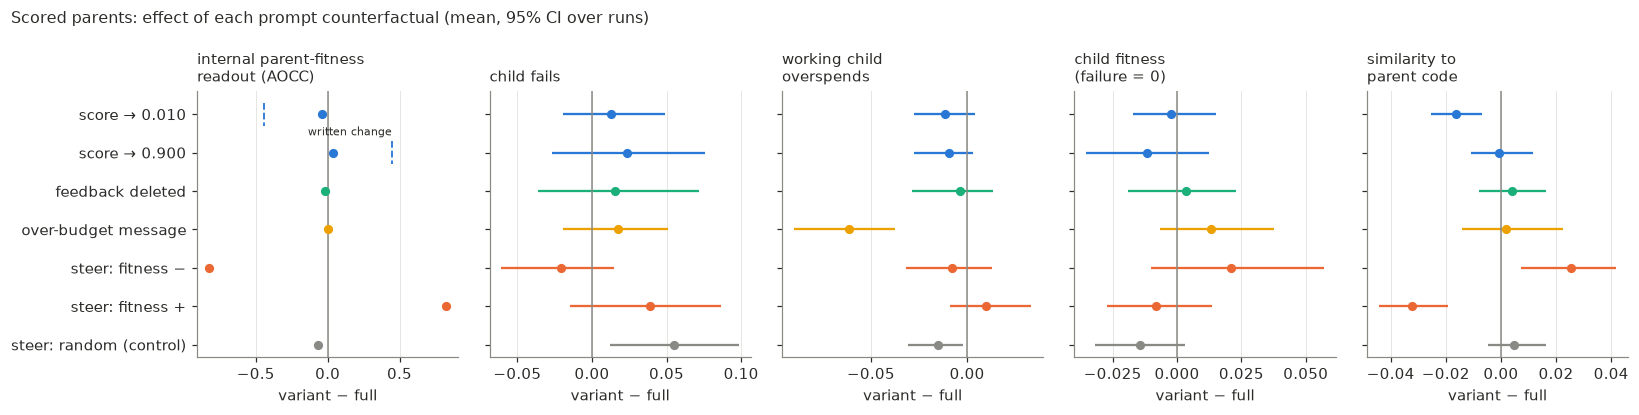

In [2]:
sc = samples[samples["stratum"] == "scored"]
written = {
    "score_low": (0.010 - sc.loc[sc.variant == "score_low", "parent_fitness"]).mean(),
    "score_high": (0.900 - sc.loc[sc.variant == "score_high", "parent_fitness"]).mean(),
}
variants = ["score_low", "score_high", "no_feedback", "budget_msg",
            "steer_down", "steer_up", "steer_random"]
labels = {"score_low": "score → 0.010", "score_high": "score → 0.900",
          "no_feedback": "feedback deleted", "budget_msg": "over-budget message",
          "steer_down": "steer: fitness −", "steer_up": "steer: fitness +",
          "steer_random": "steer: random (control)"}
colors = {"score_low": SERIES[0], "score_high": SERIES[0], "no_feedback": SERIES[2],
          "budget_msg": SERIES[3], "steer_down": SERIES[1], "steer_up": SERIES[1],
          "steer_random": NEUTRAL}
panels = [("pf_L15", "internal parent-fitness\nreadout (AOCC)"),
          ("failed", "child fails"),
          ("over_budget", "working child\noverspends"),
          ("score", "child fitness\n(failure = 0)"),
          ("similarity", "similarity to\nparent code")]
e = eff[eff["stratum"] == "scored"]
fig, axes = plt.subplots(1, len(panels), figsize=(15, 3.8), sharey=True)
y = np.arange(len(variants))
for ax, (m, title) in zip(axes, panels):
    d = e[e["metric"] == m].set_index("variant").reindex(variants)
    for i, v in enumerate(variants):
        if np.isnan(d.loc[v, "effect"]):
            continue
        ax.errorbar(d.loc[v, "effect"], i,
                    xerr=[[d.loc[v, "effect"] - d.loc[v, "ci_low"]],
                          [d.loc[v, "ci_high"] - d.loc[v, "effect"]]],
                    fmt="o", color=colors[v], ms=5, lw=1.5)
    ax.axvline(0, color=NEUTRAL, lw=1)
    if m == "pf_L15":
        for v, w in written.items():
            i = variants.index(v)
            ax.plot([w, w], [i - 0.3, i + 0.3], ls="--", color=colors[v], lw=1.2)
        ax.text(written["score_high"], variants.index("score_high") - 0.45,
                "written change", ha="right", fontsize=7.5, color=INK)
    ax.set_title(title, loc="left", fontsize=9.5, color=INK)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("variant − full")
axes[0].set_yticks(y)
axes[0].set_yticklabels([labels[v] for v in variants])
axes[0].invert_yaxis()
fig.suptitle("Scored parents: effect of each prompt counterfactual (mean, 95% CI over runs)",
             x=0.01, ha="left", fontsize=10.5, color=INK)
fig.tight_layout()
fig.savefig(res / "counterfactuals_scored.png", dpi=150, bbox_inches="tight")

In [3]:
show = ["failed", "over_budget", "score", "similarity", "prefix", "pf_L15", "cf_L21"]
e.pivot(index="variant", columns="metric", values="effect")[show].round(3)

metric,failed,over_budget,score,similarity,prefix,pf_L15,cf_L21
variant,,,,,,,
budget_msg,0.018,-0.062,0.013,0.002,0.105,0.002,-0.015
no_feedback,0.016,-0.004,0.003,0.004,0.198,-0.017,-0.044
score_high,0.023,-0.010,-0.012,-0.001,0.328,0.038,-0.003
score_low,0.013,-0.011,-0.003,-0.016,0.256,-0.039,0.014
steer_down,-0.021,-0.008,0.021,0.025,0.112,-0.826,-0.024
steer_random,0.055,-0.015,-0.014,0.005,0.109,-0.065,-0.104
steer_up,0.039,0.010,-0.008,-0.032,0.063,0.826,0.239


## 2. Crashed parents: is the error message used to fix the code?

`same_error`: the child fails with the parent's exception type.
`error_line_kept`: the line named in the error is still in the child's code.

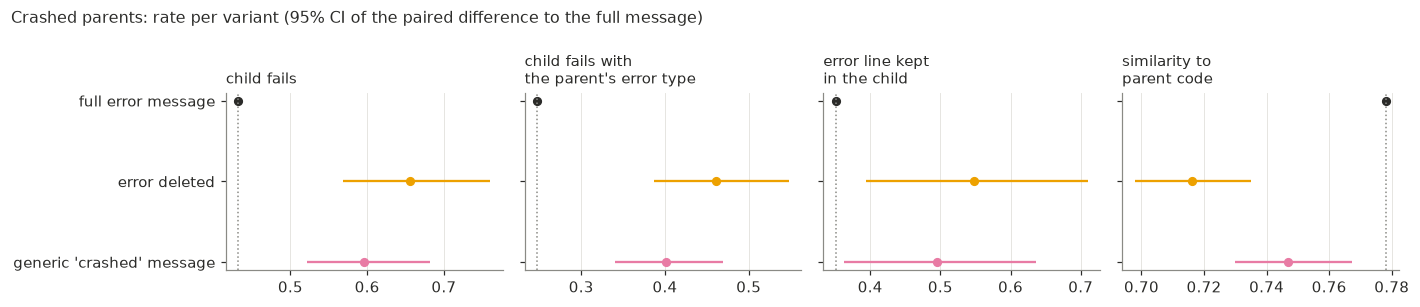

In [4]:
ev = ["no_error", "error_generic"]
elabels = {"full": "full error message", "no_error": "error deleted",
           "error_generic": "generic 'crashed' message"}
mets = [("failed", "child fails"), ("same_error", "child fails with\nthe parent's error type"),
        ("error_line_kept", "error line kept\nin the child"), ("similarity", "similarity to\nparent code")]
er = means[means["stratum"] == "error"].set_index("variant")
ee = eff[eff["stratum"] == "error"]
fig, axes = plt.subplots(1, len(mets), figsize=(13, 2.8), sharey=True)
order = ["full"] + ev
for ax, (m, title) in zip(axes, mets):
    for i, v in enumerate(order):
        mean = er.loc[v, m]
        if v == "full":
            ax.plot(mean, i, "o", color=INK, ms=5)
            continue
        d = ee[(ee.metric == m) & (ee.variant == v)].iloc[0]
        base = d["full"]
        ax.errorbar(base + d["effect"], i,
                    xerr=[[d["effect"] - d["ci_low"]], [d["ci_high"] - d["effect"]]],
                    fmt="o", color=SERIES[3] if v == "no_error" else SERIES[4], ms=5, lw=1.5)
    ax.axvline(er.loc["full", m], color=NEUTRAL, lw=1, ls=":")
    ax.set_title(title, loc="left", fontsize=9.5, color=INK)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels([elabels[v] for v in order])
axes[0].invert_yaxis()
fig.suptitle("Crashed parents: rate per variant (95% CI of the paired difference to the full message)",
             x=0.01, ha="left", fontsize=10.5, color=INK)
fig.tight_layout()
fig.savefig(res / "counterfactuals_error.png", dpi=150, bbox_inches="tight")

In [5]:
ee.pivot(index="variant", columns="metric", values="effect")[
    ["failed", "same_error", "error_line_kept", "similarity", "prefix", "score"]].round(3)

metric,failed,same_error,error_line_kept,similarity,prefix,score
variant,,,,,,
error_generic,0.164,0.154,0.144,-0.031,0.067,-0.025
no_error,0.224,0.214,0.197,-0.062,0.038,-0.044


## 3. Attribution graphs: where does the influence on the edit token come from?

Edit token: the first token where the recorded child departs from the parent's code.
Copy token: the first token of the nearest earlier line copied unchanged. Share of the
graph's total influence on the target logit, by the prompt span at which each node
(feature, error node or token embedding) sits.

In [6]:
ag_paths = sorted(data_dir(EXP, "processed", TAG).glob("attribution_graphs-*.jsonl"))
ag = pd.DataFrame([json.loads(l) for p in ag_paths for l in open(p)])
share = pd.json_normalize(ag["share"]).fillna(0)
ag = pd.concat([ag.drop(columns=["share"]), share.add_prefix("share_")], axis=1)
span_order = ["feedback", "parent_code", "response", "population", "task",
              "parent_description", "operator", "format", "template"]
span_labels = {"feedback": "feedback / error", "parent_code": "parent code",
               "response": "response so far", "population": "population",
               "task": "task", "parent_description": "parent description",
               "operator": "operator", "format": "format", "template": "chat template"}
cols = [f"share_{s}" for s in span_order if f"share_{s}" in ag]
summary = ag.groupby(["stratum", "target"])[cols].mean()
summary["n"] = ag.groupby(["stratum", "target"]).size()
summary["replacement"] = ag.groupby(["stratum", "target"])["replacement_score"].mean()
summary.round(3)

share_feedback  share_parent_code  share_response  \
stratum target                                                      
error   copy             0.015               0.25           0.584   
        edit             0.018               0.12           0.657   

                share_population  share_task  share_parent_description  \
stratum target                                                           
error   copy               0.026       0.068                     0.012   
        edit               0.028       0.073                     0.012   

                share_operator  share_format  share_template  n  replacement  
stratum target                                                                
error   copy             0.004         0.011           0.030  1        0.107  
        edit             0.008         0.019           0.065  1        0.083

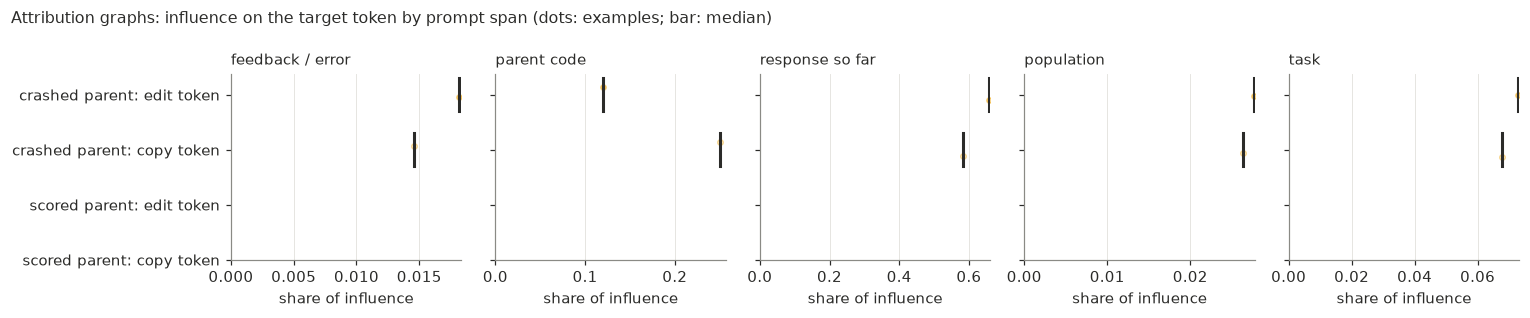

In [7]:
groups = [("error", "edit", "crashed parent: edit token"),
          ("error", "copy", "crashed parent: copy token"),
          ("scored", "edit", "scored parent: edit token"),
          ("scored", "copy", "scored parent: copy token")]
spans_plot = [s for s in ["feedback", "parent_code", "response", "population", "task"]
              if f"share_{s}" in ag]
fig, axes = plt.subplots(1, len(spans_plot), figsize=(14, 2.9), sharey=True)
rng = np.random.default_rng(0)
for ax, s in zip(axes, spans_plot):
    for i, (st, tg, _) in enumerate(groups):
        v = ag.loc[(ag.stratum == st) & (ag.target == tg), f"share_{s}"].to_numpy()
        if len(v) == 0:
            continue
        c = SERIES[3] if st == "error" else SERIES[0]
        ax.plot(v, i + rng.uniform(-0.15, 0.15, len(v)), "o", ms=3.5, alpha=0.45,
                color=c, mfc=c if tg == "edit" else "none")
        ax.plot([np.median(v)] * 2, [i - 0.3, i + 0.3], color=INK, lw=2)
    ax.set_title(span_labels[s], loc="left", fontsize=9.5, color=INK)
    ax.set_xlim(left=0)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("share of influence")
axes[0].set_yticks(range(len(groups)))
axes[0].set_yticklabels([g[2] for g in groups])
axes[0].invert_yaxis()
fig.suptitle("Attribution graphs: influence on the target token by prompt span (dots: examples; bar: median)",
             x=0.01, ha="left", fontsize=10.5, color=INK)
fig.tight_layout()
fig.savefig(res / "attribution_graphs.png", dpi=150, bbox_inches="tight")

In [8]:
# Paired edit - copy difference in the feedback share, per stratum
w = ag.pivot_table(index=["stratum", "record_id"], columns="target", values="share_feedback")
w["diff"] = w["edit"] - w["copy"]
w.groupby("stratum")["diff"].describe().round(4)

,count,mean,std,min,25%,50%,75%,max
stratum,,,,,,,,
error,1.0,0.0036,NaN,0.0036,0.0036,0.0036,0.0036,0.0036
